# Task 2: Player Segmentation (4-class)
Target `segment`: 0 = Casual, 1 = Grinder, 2 = Social, 3 = Whale

**Pipeline:** load → audit → EDA → LightGBM + CatBoost (GPU) + KDE naive Bayes, 5-fold × 3 seeds → stacker → per-class weights for macro-F1 → write `task2` into the submission

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_auc_score
from scipy.optimize import minimize

import os, glob
# Data: this folder locally; on Kaggle the competition's 02_multiclass_classification folder (searched for if mounted elsewhere)
KAGGLE_DIR = '/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main'
ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    DATA_DIR = f'{KAGGLE_DIR}/02_multiclass_classification'
    if not os.path.exists(f'{DATA_DIR}/test.csv'):
        DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/02_multiclass_classification/test.csv', recursive=True)[0])
else:
    DATA_DIR = '.'
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
print('data from:', os.path.abspath(DATA_DIR))
TARGET, ID, SEED = 'segment', 'player_id', 42
NAMES = ['Casual', 'Grinder', 'Social', 'Whale']
sns.set_theme(style='whitegrid')

train = pd.read_csv(f'{DATA_DIR}/train.csv'); test = pd.read_csv(f'{DATA_DIR}/test.csv')
CAT = train.select_dtypes(exclude='number').columns.drop(ID).tolist()
RANDOM = [c for c in test.columns if c.startswith('random_metric')]
FEATS = [c for c in test.columns if c not in [ID] + RANDOM]   # datacard: random_metric_* are pure noise
for d in (train, test):
    for c in CAT: d[c] = pd.Categorical(d[c], categories=sorted(train[c].dropna().unique()))
y = train[TARGET].values
print(train.shape, test.shape, '| features used:', len(FEATS), '| categorical:', len(CAT))
print(train[TARGET].value_counts().sort_index().rename(dict(enumerate(NAMES))))

data from: /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/02_multiclass_classification
(104000, 46) (25889, 45) | features used: 41 | categorical: 10
segment
Casual     40957
Grinder    26032
Social     21029
Whale      15982
Name: count, dtype: int64


## 1. Audit

In [2]:
print('duplicate ids:', train[ID].duplicated().sum(), '| train/test id overlap:', train[ID].isin(test[ID]).sum())
na = pd.DataFrame({'train': train[FEATS].isna().mean()}).round(3)
print('missing share  min/median/max:', na.train.min(), na.train.median(), na.train.max())
na.sort_values('train', ascending=False).head(8)

duplicate ids: 0 | train/test id overlap: 0
missing share  min/median/max: 0.075 0.077 0.308


,train
payment_method,0.308
region,0.262
team_play_percentage,0.078
ranked_participation_rate,0.078
platform,0.078
engagement_level,0.078
avg_monthly_spending,0.078
play_frequency,0.077


## 2. EDA

loyalty_tier        0.385
engagement_level    0.383
language            0.008
device_type         0.007
skill_tier          0.007
player_type_tag     0.004
region              0.004
platform            0.003
payment_method      0.003
account_status      0.003


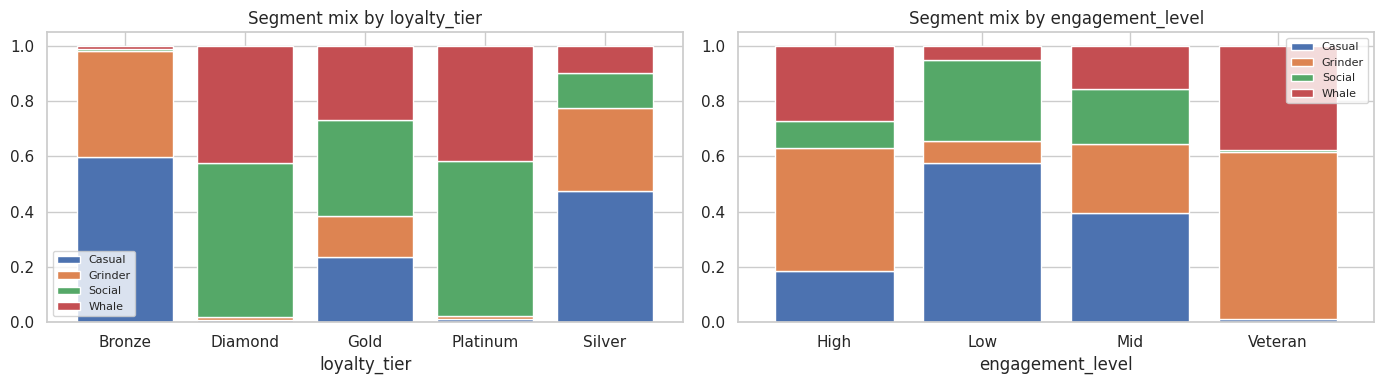

In [3]:
# Which categoricals carry signal? Max share of each class across a column's categories (flat = noise)
base = pd.Series(y).value_counts(normalize=True).sort_index().values
spread = {c: (pd.crosstab(train[c], y, normalize='index') - base).abs().max().max() for c in CAT}
print(pd.Series(spread).sort_values(ascending=False).round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ['loyalty_tier', 'engagement_level']):
    pd.crosstab(train[c], y, normalize='index').rename(columns=dict(enumerate(NAMES))).plot.bar(stacked=True, ax=ax, rot=0, width=.8)
    ax.set_title(f'Segment mix by {c}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

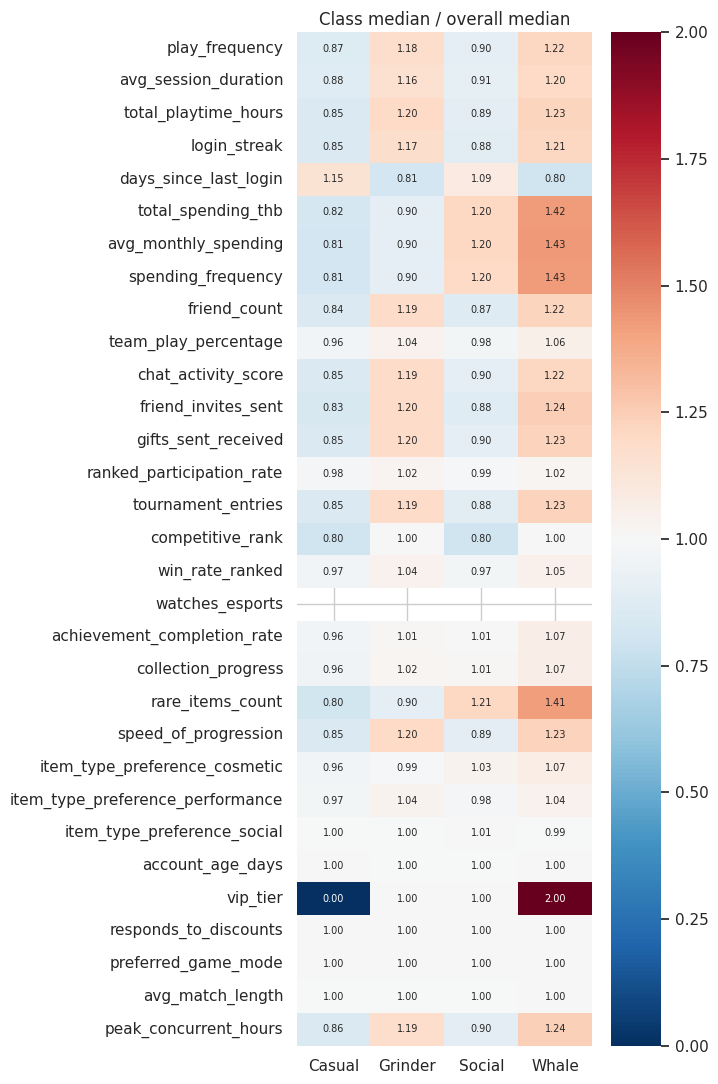

In [4]:
# Numeric features: class medians (scaled by overall median) show which segment each feature separates
num = [c for c in FEATS if c not in CAT]
med = train.groupby(TARGET)[num].median().T
med.columns = NAMES
rel = med.div(train[num].median().replace(0, np.nan), axis=0)
plt.figure(figsize=(7, 11)); sns.heatmap(rel, cmap='RdBu_r', center=1, vmin=0, vmax=2, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Class median / overall median'); plt.tight_layout(); plt.show()

In [5]:
# Noise check for random_metric_*
print('random_metric class medians:'); print(train.groupby(TARGET)[RANDOM].median().round(3))

random_metric class medians:
         random_metric_1  random_metric_2  random_metric_3
segment                                                   
0                496.218              0.5             99.0
1                499.645              0.5            100.0
2                492.299              0.5             99.5
3                497.690              0.5             99.0


### Key insights
1. **`random_metric_1-3` are noise** (the datacard says so and the class medians are identical), so they're dropped.
2. Of the 10 categoricals, **only `loyalty_tier` and `engagement_level` carry signal**; the other 8 have the same class mix in every category. Dropping them was tested and changed nothing (macro-F1 0.7507 vs 0.7511), so they're kept and the trees ignore them.
3. `loyalty_tier` is the strongest feature (about 29% of gain), followed by `engagement_level`, `vip_tier`, `days_since_last_login` and the spending features. Whales separate on spending, Grinders on playtime and recency.
4. Missing values (about 7.7% per column) are left as NaN: LightGBM handles them natively, and CatBoost gets an explicit `'NA'` category.

## 3. Models: LightGBM + CatBoost (GPU), 5-fold × 3 seeds
LightGBM uses the tuned parameters saved in `task2_lgb_params.json` (attach it on Kaggle; without it Optuna searches again and the parameters differ). 5 seeds were also tried: OOF macro-F1 0.7567 vs 0.7568 with 3 seeds, so 3 are kept.

In [6]:
N_FOLDS, SEEDS = 5, [42, 7, 2024]   # 5 fold splits x 3 seeds, averaged
X, X_te = train[FEATS], test[FEATS]
# CatBoost wants string categories without NaN
Xc, Xc_te = X.copy(), X_te.copy()
for d in (Xc, Xc_te):
    for c in CAT: d[c] = d[c].astype(object).fillna('NA')

def run_cv(fit, Xtr, Xts):
    oof, pred = np.zeros((len(Xtr), 4)), np.zeros((len(Xts), 4))
    for s in SEEDS:
        for a, b in StratifiedKFold(N_FOLDS, shuffle=True, random_state=s).split(Xtr, y):
            m = fit(Xtr.iloc[a], y[a], Xtr.iloc[b], y[b], s)
            oof[b] += m.predict_proba(Xtr.iloc[b]) / len(SEEDS)
            pred += m.predict_proba(Xts) / (len(SEEDS) * N_FOLDS)
    return oof, pred

def report(name, o): print(f'{name}: acc={accuracy_score(y, o.argmax(1)):.4f}  macro-F1={f1_score(y, o.argmax(1), average="macro"):.4f}')

LGB_PARAMS = dict(n_estimators=10000, learning_rate=.03, num_leaves=31, min_child_samples=40,
                  subsample=.8, subsample_freq=1, colsample_bytree=.6, reg_lambda=2, verbose=-1)
def fit_lgb(xa, ya, xb, yb, s):
    return lgb.LGBMClassifier(**LGB_PARAMS, random_state=s).fit(
        xa, ya, eval_set=[(xb, yb)], callbacks=[lgb.early_stopping(200, verbose=False)])

### Hyperparameter tuning (Optuna)
Optuna's TPE sampler searches LightGBM's tree parameters. Each trial is scored by **3-fold OOF log-loss** (learning rate 0.05 for speed): log-loss rewards better probabilities everywhere and is much less noisy than macro-F1 of the argmax, while the class weights in section 4 turn the probabilities into the macro-F1 decision. Trial 0 is the hand-set parameters, so the tuned set is only used if it beats them.

In [7]:
import os, json, optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE_KEYS = ('num_leaves', 'min_child_samples', 'colsample_bytree', 'subsample', 'reg_lambda', 'reg_alpha')
SPACE = lambda t: dict(num_leaves=t.suggest_int('num_leaves', 15, 127, log=True),
                       min_child_samples=t.suggest_int('min_child_samples', 10, 200, log=True),
                       colsample_bytree=t.suggest_float('colsample_bytree', .3, 1.),
                       subsample=t.suggest_float('subsample', .5, 1.),
                       reg_lambda=t.suggest_float('reg_lambda', 1e-3, 30, log=True),
                       reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True))

def tune(name, score, hand, n_trials=40, timeout=20 * 60):
    # Optuna TPE search of LightGBM tree parameters (higher score = better). Trial 0 is the hand-set values,
    # so the result is never worse on this CV. Saved to <name>.json and reused on later runs (delete it to search again).
    path = f'{name}.json'
    if not os.path.exists(path):   # on Kaggle: saved parameters attached as a dataset
        path = next(iter(glob.glob(f'/kaggle/input/**/{name}.json', recursive=True)), path)
    if os.path.exists(path):
        r = json.load(open(path))
        print(f"{name}: loaded {path} | hand-set {r['hand_score']:.5f} -> best {r['best_score']:.5f} after {r['trials']} trials")
        return {**hand, **r['params']}
    start = {k: hand.get(k, 1e-3) for k in TUNE_KEYS}
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42, multivariate=True))
    study.enqueue_trial(start)
    study.optimize(lambda t: score({**hand, **SPACE(t)}), n_trials=n_trials, timeout=timeout)
    h, b = study.trials[0].value, study.best_value
    params = study.best_params if b > h else start
    json.dump({'params': params, 'hand_score': h, 'best_score': b, 'trials': len(study.trials)}, open(path, 'w'), indent=1)
    print(f'{name}: {len(study.trials)} trials | hand-set {h:.5f} -> best {b:.5f} ({b - h:+.5f})',
          '| tuned parameters used' if b > h else '| hand-set parameters kept')
    print('   chosen:', pd.Series(params, dtype=object).to_string().replace(chr(10), ' | '))
    return {**hand, **params}
from sklearn.metrics import log_loss

def score_t2(params):
    oof = np.zeros((len(X), 4))
    for a, b in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, y):
        m = lgb.LGBMClassifier(**{**params, 'learning_rate': .05}, random_state=SEED).fit(
            X.iloc[a], y[a], eval_set=[(X.iloc[b], y[b])], callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[b] = m.predict_proba(X.iloc[b])
    return -log_loss(y, oof)

LGB_PARAMS = tune('task2_lgb_params', score_t2, LGB_PARAMS)

task2_lgb_params: 22 trials | hand-set -0.61709 -> best -0.61591 (+0.00118) | tuned parameters used
   chosen: num_leaves                 17 | min_child_samples         152 | colsample_bytree     0.330387 | subsample            0.665161 | reg_lambda           0.056167 | reg_alpha            0.319474


In [8]:
oof_lgb, pred_lgb = run_cv(fit_lgb, X, X_te); report('LightGBM', oof_lgb)

LightGBM: acc=0.7679  macro-F1=0.7533


In [9]:
from catboost import CatBoostClassifier
from catboost.utils import get_gpu_device_count
CAT_DEVICE = 'GPU' if get_gpu_device_count() > 0 else 'CPU'
def fit_cat(xa, ya, xb, yb, s):
    return CatBoostClassifier(iterations=8000, learning_rate=.06, depth=6, loss_function='MultiClass',
                              task_type=CAT_DEVICE, od_type='Iter', od_wait=300, random_seed=s, verbose=0,
                              cat_features=CAT).fit(xa, ya, eval_set=(xb, yb))
oof_cat, pred_cat = run_cv(fit_cat, Xc, Xc_te); report(f'CatBoost ({CAT_DEVICE})', oof_cat)

CatBoost (GPU): acc=0.7680  macro-F1=0.7530


### Third model: kernel-density naive Bayes
The features are generated almost independently of each other (pairs of features carry no extra signal), which is exactly what naive Bayes assumes. It models each feature's distribution per class on its own: numeric features as a smoothed histogram on the training-quantile scale (200 bins, Gaussian smoothing of 1.5 bins; a missing value is its own outcome), categorical features as smoothed frequencies. It is a very different kind of model from the trees, so the stacker can use it where the trees are noisy. It is fitted on the training part of every fold only, like the other models.

In [10]:
from scipy.ndimage import gaussian_filter1d
class KDENB:
    def __init__(self, bins=200, bw=1.5, alpha=1.): self.bins, self.bw, self.alpha = bins, bw, alpha
    def fit(self, X, y):
        y = np.asarray(y); self.prior = np.log(np.bincount(y, minlength=4) / len(y)); self.tabs = {}
        for c in X.columns:
            if c in CAT:
                v = X[c].astype(str).values; cats = {k: i for i, k in enumerate(pd.unique(v))}
                H = np.full((4, len(cats) + 1), self.alpha); np.add.at(H, (y, [cats[k] for k in v]), 1)   # last column: unseen category
                self.tabs[c] = ('cat', cats, np.log(H / H.sum(1, keepdims=True)))
            else:
                v = X[c].values.astype(float); ok = ~np.isnan(v)
                edges = np.unique(np.quantile(v[ok], np.linspace(0, 1, self.bins + 1))); nb = len(edges) - 1
                H = np.zeros((4, nb + 1)); np.add.at(H, (y[ok], self._bin(edges, v[ok])), 1); np.add.at(H, (y[~ok], nb), 1)   # last column: missing
                H = np.concatenate([gaussian_filter1d(H[:, :nb], self.bw, axis=1, mode='nearest') + .01 * self.alpha, H[:, nb:] + self.alpha], 1)
                self.tabs[c] = ('num', edges, np.log(H / H.sum(1, keepdims=True)))
        return self
    @staticmethod
    def _bin(edges, z): return np.clip(np.searchsorted(edges, z, side='right') - 1, 0, len(edges) - 2)
    def predict_proba(self, X):
        o = np.tile(self.prior, (len(X), 1))
        for c, (kind, ref, L) in self.tabs.items():
            if kind == 'cat': j = np.array([ref.get(k, len(ref)) for k in X[c].astype(str).values])
            else:
                z = X[c].values.astype(float); j = np.where(np.isnan(z), len(ref) - 1, self._bin(ref, np.nan_to_num(z)))
            o += L[:, j].T
        o = np.exp(o - o.max(1, keepdims=True)); return o / o.sum(1, keepdims=True)

oof_nb, pred_nb = run_cv(lambda xa, ya, xb, yb, s: KDENB().fit(xa, ya), X, X_te); report('KDE naive Bayes', oof_nb)

KDE naive Bayes: acc=0.7638  macro-F1=0.7486


## 4. Stacking + per-class weights for macro-F1
A multinomial logistic regression learns how to combine the three models from their log-probabilities (12 inputs). It can trust one model more for some classes than for others, which a single blend weight cannot. The stacker is cross-validated on its own 5 folds, so its out-of-fold score stays honest. Then each class's probability is scaled by a weight found on the stacked OOF, which helps the smaller classes under macro-F1.

| combination (OOF, after class weights) | macro-F1 |
|---|---|
| weighted average of LightGBM and CatBoost | 0.7554 |
| **logistic-regression stacker** | **0.7565** (better in 4 of 5 folds) |
| stacker with a third model (HistGradientBoosting) | 0.7564 (not used: no gain over two models) |
| **stacker with KDE naive Bayes as a third input** | about +0.0007 over the two-model stacker on 4 different stacker splits (better in 4, 4, 4 and 5 of 5 folds; class weights tuned on 4 folds and scored on the 5th) |

Stacker: acc=0.7693  macro-F1=0.7548
class weights: {'Casual': np.float64(0.826), 'Grinder': np.float64(0.994), 'Social': np.float64(1.07), 'Whale': np.float64(1.145)}
Stacker + class weights: acc=0.7692  macro-F1=0.7570
macro-F1 per stacker fold: [0.7552, 0.7539, 0.7588, 0.7575, 0.7594]


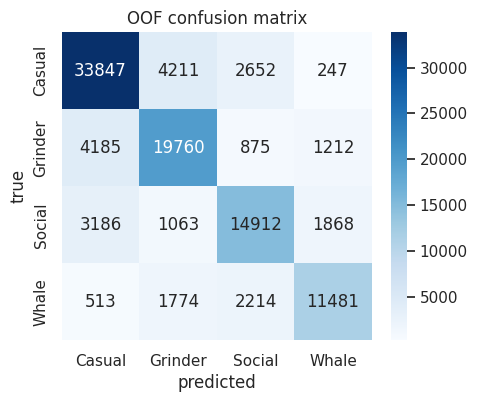

In [11]:
from sklearn.linear_model import LogisticRegression
logp = lambda *ps: np.column_stack([np.log(np.clip(p, 1e-6, 1)) for p in ps])
Z, Z_te = logp(oof_lgb, oof_cat, oof_nb), logp(pred_lgb, pred_cat, pred_nb)
stack_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Z, y))
oof = np.zeros((len(y), 4))
for a, b in stack_folds:
    oof[b] = LogisticRegression(C=.5, max_iter=2000).fit(Z[a], y[a]).predict_proba(Z[b])
pred = LogisticRegression(C=.5, max_iter=2000).fit(Z, y).predict_proba(Z_te)   # final stacker on all OOF rows
report('Stacker', oof)

CW = np.abs(minimize(lambda w: -f1_score(y, (oof * np.abs(w)).argmax(1), average='macro'),
                     np.ones(4), method='Nelder-Mead', options={'xatol': 1e-3, 'maxiter': 400}).x)
print('class weights:', dict(zip(NAMES, CW.round(3)))); report('Stacker + class weights', oof * CW)
print('macro-F1 per stacker fold:', [round(f1_score(y[b], (oof[b] * CW).argmax(1), average='macro'), 4) for _, b in stack_folds])

cm = confusion_matrix(y, (oof * CW).argmax(1))
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=NAMES, yticklabels=NAMES)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('OOF confusion matrix'); plt.show()

## 5. Submission
Writes `task2` into `../submission.csv` and keeps the other columns (Task 1 included). If that file doesn't exist yet, it starts from `sample_submission.csv`. On Kaggle the file goes to `/kaggle/working/submission.csv`, starting from our best `submission.csv` if it is attached as a dataset (otherwise from `sample_submission.csv`).

In [12]:
import os
METRIC = 'macro_f1'   # change to 'accuracy' to use plain argmax
labels = ((pred * CW) if METRIC == 'macro_f1' else pred).argmax(1)
print('test class mix:', dict(zip(NAMES, np.bincount(labels, minlength=4) / len(labels))))
pd.DataFrame({ID: test[ID], TARGET: labels}).to_csv(f'{OUT_DIR}/submission_task2.csv', index=False)

# Full submission: locally ../submission.csv; on Kaggle our best submission.csv if it is attached as a dataset,
# otherwise the competition's sample_submission.csv (then only this task's column is real)
if ON_KAGGLE:
    full = glob.glob('/kaggle/input/**/submission.csv', recursive=True)
    SUB = full[0] if full else glob.glob('/kaggle/input/**/sample_submission.csv', recursive=True)[0]
    OUT = f'{OUT_DIR}/submission.csv'
else:
    SUB = '../submission.csv' if os.path.exists('../submission.csv') else '../sample_submission.csv'
    OUT = '../submission.csv'
sub = pd.read_csv(SUB)
assert len(sub) == len(test), 'row count mismatch'
sub['task2'] = labels   # assumes row i of the submission = row i of test.csv
sub.to_csv(OUT, index=False)
print(f'updated {OUT} from {SUB}'); sub.head()

test class mix: {'Casual': np.float64(0.4026420487465719), 'Grinder': np.float64(0.2588357989879872), 'Social': np.float64(0.19722662134497276), 'Whale': np.float64(0.14129553092046815)}
updated /kaggle/working/submission.csv from /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/sample_submission.csv


,id,task1,task2,task3,task4,task5
0,ANS00001,1.0,3,2983.20,0.0,1.0
1,ANS00002,0.0,2,529.00,1.0,1.0
2,ANS00003,1.0,2,15682.45,2.0,0.0
3,ANS00004,0.0,1,7200.00,0.0,1.0
4,ANS00005,NaN,0,NaN,NaN,NaN
